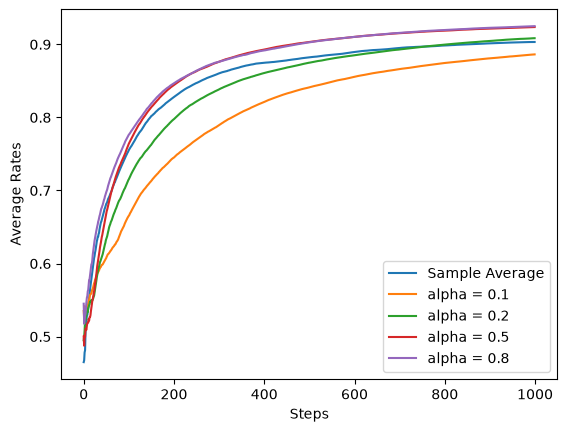

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from bandit import Agent


class NonStatBandit:
    def __init__(self, arms=10):
        self.arms = arms
        self.rates = np.random.rand(arms)

    def play(self, arm):
        rate = self.rates[arm]
        self.rates += 0.1 * np.random.randn(self.arms)  # 노이즈 추가
        if rate > np.random.rand():
            return 1
        else:
            return 0
#__________

class AlphaAgent:
    def __init__(self, epsilon, alpha, actions=10):
        self.epsilon = epsilon
        self.Qs = np.zeros(actions)
        self.alpha = alpha  # 고정값 α

    def update(self, action, reward):
        # α로 갱신
        self.Qs[action] += (reward - self.Qs[action]) * self.alpha

    def get_action(self):
        if np.random.rand() < self.epsilon:
            return np.random.randint(0, len(self.Qs))
        return np.argmax(self.Qs)


runs = 200
steps = 1000
epsilon = 0.1
# alpha = 0.8 고정 alpha 값
alpha_values = [0.1, 0.2, 0.5, 0.8]

# agent_types = ['sample average', 'alpha const update']
results = {}

# 1. Sample Average 방식
all_rates = np.zeros((runs, steps))

for run in range(runs):
    bandit = NonStatBandit()
    agent = Agent(epsilon)

    total_reward = 0

    for step in range(steps):
        action = agent.get_action()
        reward = bandit.play(action)
        agent.update(action, reward)

        total_reward += reward
        all_rates[run, step] = total_reward / (step + 1)

results['Sample Average'] = np.average(all_rates, axis=0)


# 2. Alpha 값별 실험
for alpha in alpha_values:

    all_rates = np.zeros((runs, steps))

    for run in range(runs):
        bandit = NonStatBandit()
        agent = AlphaAgent(epsilon, alpha)

        total_reward = 0

        for step in range(steps):
            action = agent.get_action()
            reward = bandit.play(action)
            agent.update(action, reward)

            total_reward += reward
            all_rates[run, step] = total_reward / (step + 1)

    results[f'alpha = {alpha}'] = np.average(all_rates, axis=0)

# [그림 1-20] 표본 평균과 고정값 α에 의한 갱신 비교
plt.figure()
plt.ylabel('Average Rates')
plt.xlabel('Steps')
for key, avg_rates in results.items():
    plt.plot(avg_rates, label=key)
plt.legend()
plt.show()